# NN Training to Substitute LUT

## Setup
Set-up Keras (in order to use nnodely) in configuration "torch" to use PyTorch.
Import libraries to navigate repository, generate figures and open `.np` files (LUT table).

In [5]:
import os
os.environ["KERAS_BACKEND"] = "torch"

%load_ext autoreload
%autoreload 2

import json
import time
import matplotlib.pyplot as plt
import nnodely
import numpy as np

print(f"nnodely version: {nnodely.__version__}")
print(f"Backend used: {os.environ.get('KERAS_BACKEND')}")
print("Setup completed!")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
nnodely version: 2.0.0
Backend used: torch
Setup completed!


## Convert `nc` to `csv` & Rename Variable
To better visualize the LUT, convert the `.nc` file into a `.csv` (step not strictly necessary as we will use `nnodely` directly with the `.nc` file).

| Original Name | New Name |
| :--- | :--- |
| `__xarray_dataarray_variable__` | `activation_value` |
| `min_torque` | `torque_min` |
| `max_torque` | `torque_max` |

In [6]:
from src.lut import LUT

PATH_FILE_NC = "models/W=0.2/comb_lut_W=0.2.nc"
PATH_FILE_CSV = "models/W=0.2/comb_lut_W=0.2.csv"

OLD_VAR_NAME = "max_torque"
NEW_VAR_NAME = "torque_max"

my_lut = LUT(PATH_FILE_NC)

my_lut.rename_variable(OLD_VAR_NAME, NEW_VAR_NAME)
my_lut.to_csv(PATH_FILE_CSV)

File NC updated in: models/W=0.2/comb_lut_W=0.2.nc
File CSV saved in: models/W=0.2/comb_lut_W=0.2.csv
Number of valid rows of CSV: 6882


## LUT Upload
Open the `.nc` file and remove the NaN.
Build the LUT Matrix starting from the `.nc` file.
The numer of rows of the LUT matrix should be the valid rows of CSV divided by 6.
In the `.nc` file, values are stored as `float64`, but PyTorch will convert it into `float32`.

In [23]:
from src.lut import LUT

# modify this if you want to upload another np
LUT_PATH = PATH_FILE_NC

my_lut = LUT(LUT_PATH)
my_lut.load_data()

Dataset LUT uploaded!
LUT matrix dimension: (1147, 6)


## LUT Visualization
Heat-map to visualize the intensity of the muscle.
Insert negative values for `ANGLE_REQ` or `TAU_REQ` if you wanto to analize the general case.

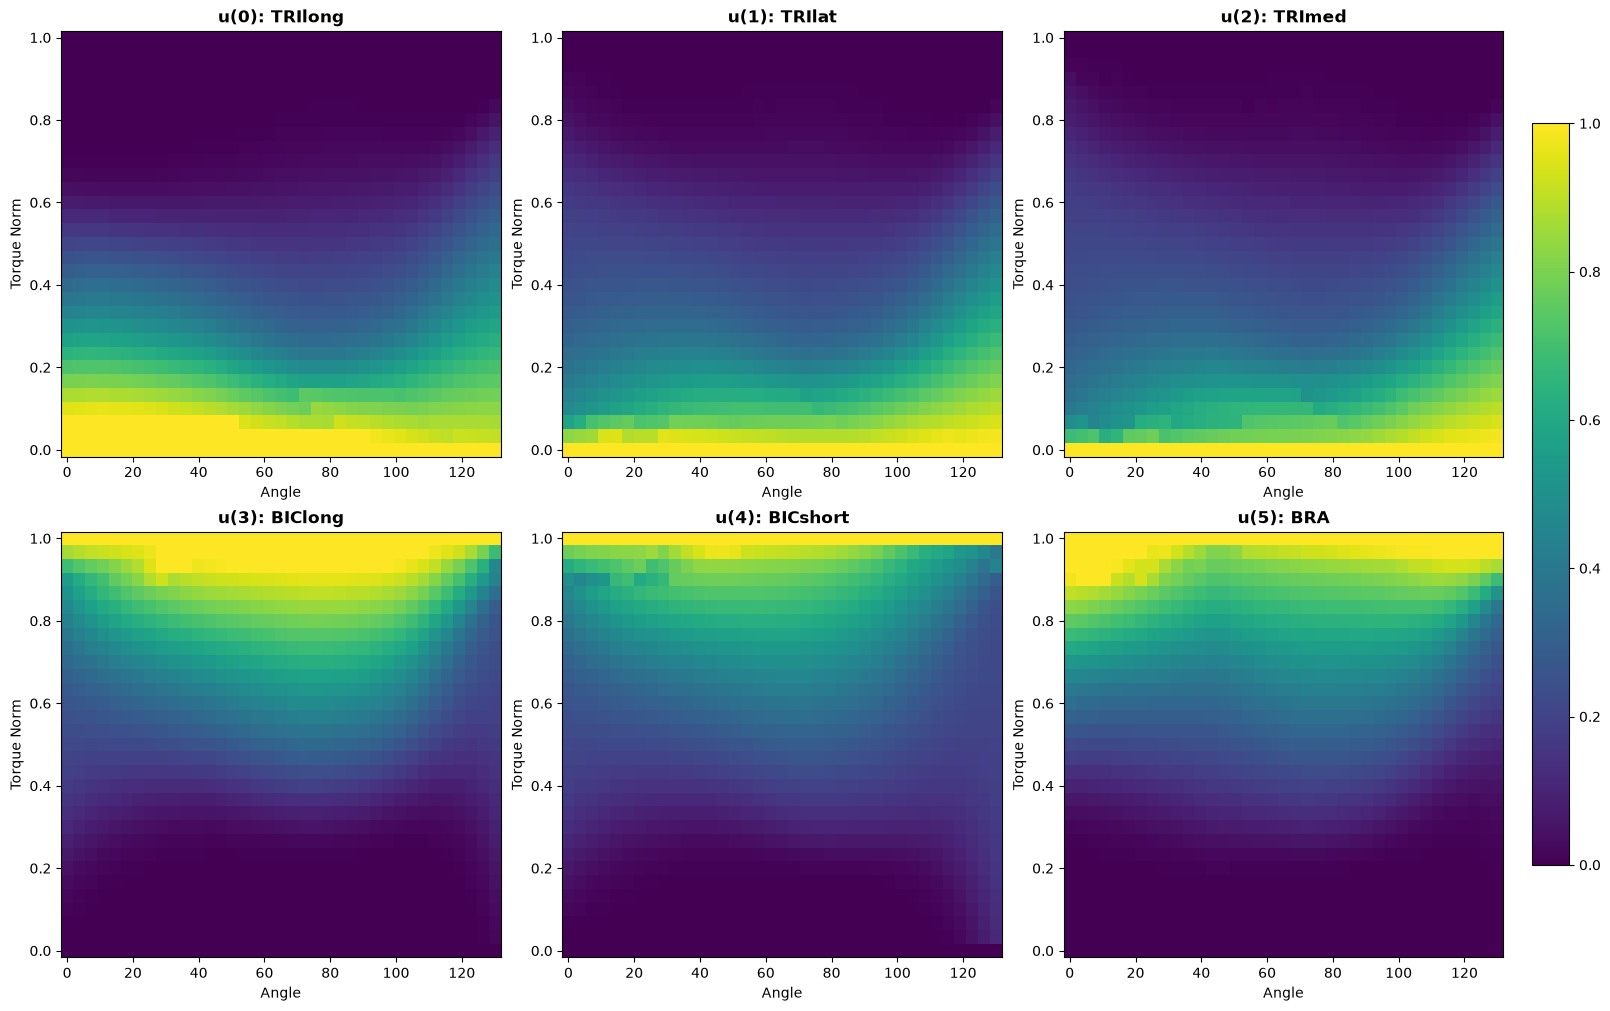

In [85]:
ANGLE_REQ = 45.0
TAU_REQ = 0.5

my_lut.plot_heatmaps()
#my_lut.plot_heatmaps(ANGLE_REQ, TAU_REQ)

## NN Setup
We need to define the number of layers and of neurons of the Neural Network.
The input is $x_{in}=[\theta, \tau_{norm}]^T$ and output is $u_{out}=[u(0),\dots, u(5)]^T$.

Note that it is necessary to pre-process the data. Due to the fact that $\tau_{norm} \in [0,1]$ and $\theta \in [0°,130°]$, variation of $\tau_{norm}$ will be ininfluent to the NN weight variation. Therefore, we neet to normalize the inputs of the dataset.

In [46]:
from src.nn_model_from_lut import NN_model_from_LUT

NN_NAME = "comb_lut_W=0.2_nn"
NUM_HIDDEN_LAYERS = 2
HIDDEN_UNITS = 32
ACTIVATION_MODE = "relu"

my_nn_model = NN_model_from_LUT(NN_NAME, my_lut)

my_nn_model.define_structure(NUM_HIDDEN_LAYERS, HIDDEN_UNITS, ACTIVATION_MODE)

Architecture of the NN: 2 layers of 32 neurons each.


Model: "comb_lut_W=0.2_nn_train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ angle (InputLayer)  │ (None, 1, 1)      │          0 │ -                 │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow73      │ (None, 1, 1)      │          0 │ angle[0][0]       │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant3           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Subtract74          │ (None, 1, 1)      │          0 │ SampleWindow73[0… │
│ (BinaryOpImpl)      │                   │            │ Constant3[5][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Constant5           │ (None, 1, 1)      │          1 │ angle[0][0]       │
│ (ConstantImpl)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ torque_norm         │ (None, 1, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Divide75            │ (None, 1, 1)      │          0 │ Subtract74[0][0], │
│ (BinaryOpImpl)      │                   │            │ Constant5[5][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow77      │ (None, 1, 1)      │          0 │ torque_norm[0][0] │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Concatenate76       │ (None, 2, 1)      │          0 │ Divide75[0][0],   │
│ (ConcatenateImpl)   │                   │            │ SampleWindow77[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear79            │ (None, 32, 1)     │         96 │ Concatenate76[0]… │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU78 (ReLU)       │ (None, 32, 1)     │          0 │ Linear79[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear81            │ (None, 32, 1)     │      1,056 │ ReLU78[0][0]      │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ ReLU80 (ReLU)       │ (None, 32, 1)     │          0 │ Linear81[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ activations_target  │ (None, 6, 1)      │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Linear82            │ (None, 6, 1)      │        198 │ ReLU80[0][0]      │
│ (LinearImpl)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ SampleWindow84      │ (None, 6, 1)      │          0 │ activations_targ… │
│ (SampleWindowImpl)  │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Clamp83 (ClampImpl) │ (None, 6, 1)      │          0 │ Linear82[0][0]    │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 1,352 (5.28 KB)

 Trainable params: 1,350 (5.27 KB)

 Non-trainable params: 2 (8.00 B)

## NN Training

shuffle=True,       # Rimescola i batch a ogni epoca per evitare bias di ordinamento

In [47]:
EPOCHS = 100
BATCH_SIZE = 16
LEARNING_RATE = 1e-3

my_nn_model.train(EPOCHS, BATCH_SIZE, LEARNING_RATE)

Number of rows in the dataset: 1147
Training for 100 epochs...

================= nnodely Training =================
|  Epoch   |comb_lut_W=0.2_nn_l|       Total       |
|          |        Loss       |        Loss       |
|          |  train  |   val   |  train  |   val   |
|--------------------------------------------------|
|  5/100   | 0.008256|    -    | 0.008245|    -    |
|  10/100  | 0.003855|    -    | 0.003835|    -    |
|  15/100  | 0.002512|    -    | 0.002515|    -    |
|  20/100  |  0.00199|    -    | 0.001989|    -    |
|  25/100  | 0.001701|    -    | 0.001699|    -    |
|  30/100  | 0.001498|    -    |   0.0015|    -    |
|  35/100  | 0.001381|    -    | 0.001377|    -    |
|  40/100  | 0.001246|    -    | 0.001241|    -    |
|  45/100  | 0.001172|    -    | 0.001173|    -    |
|  50/100  | 0.001065|    -    | 0.001065|    -    |
|  55/100  |0.0009829|    -    |0.0009846|    -    |
|  60/100  |0.0009404|    -    |0.0009407|    -    |
|  65/100  |0.0009019|    -    |0.0

## NN Plot Results

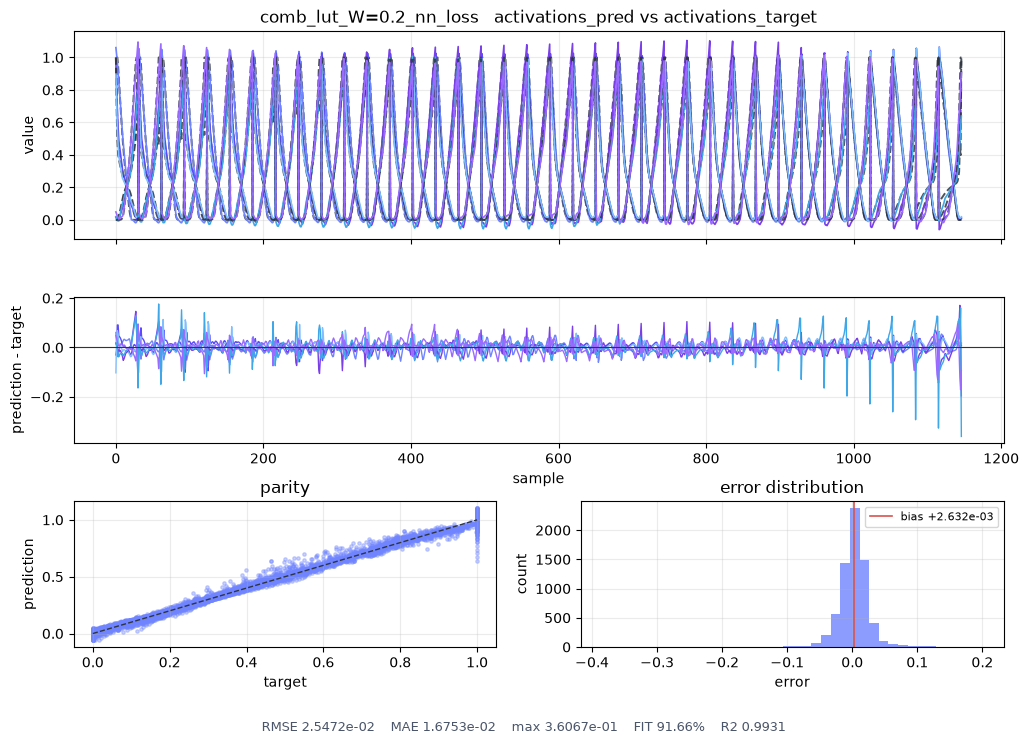

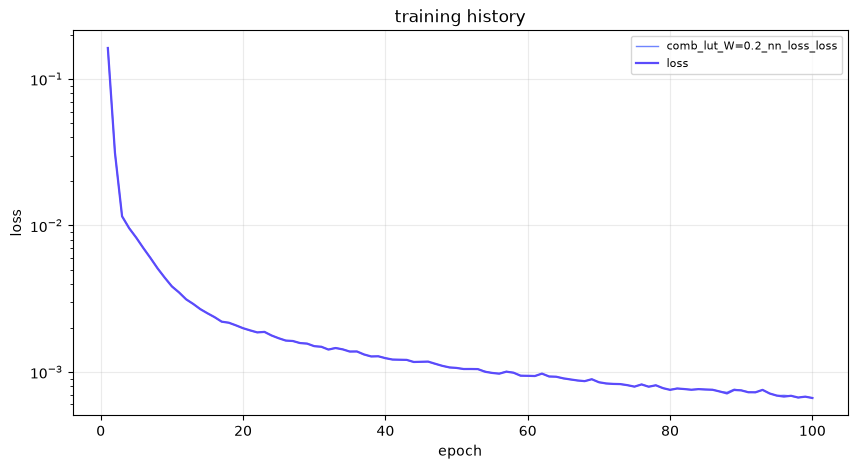

============================== nnodely Validation ==============================
Model:                        comb_lut_W=0.2_nn
Samples:                      1147
Minimizers:                   1
--------------------------------------------------------------------------------
comb_lut_W=0.2_nn_loss   (activations_pred vs activations_target)
  Loss (mean_squared_error)   6.488094e-04
  RMSE                        2.547174e-02
  MAE                         1.675301e-02
  Max error                   3.606712e-01
  Bias (mean error)           +2.632434e-03
  Error std                   2.533534e-02
  NRMSE (% of range)          2.547 %
  FIT (% variance)            91.665 %
  R2                          0.993053
  Correlation                 0.996562
--------------------------------------------------------------------------------
  Figure:                     models/W=0.2/plots\comb_lut_W_0_2_nn_comb_lut_W_0_2_nn_loss.png
  Figure:                     models/W=0.2/plots\comb_lut_W_0_2_nn_h

In [51]:
PATH_PLOT_SAVED = "models/W=0.2/plots"

my_nn_model.plot_results(PATH_PLOT_SAVED)

## NN Export Model

In [49]:
PATH_EXPORT_MODEL = "models/W=0.2"

my_nn_model.export(PATH_EXPORT_MODEL)


Model Keras saved in: models/W=0.2/comb_lut_W=0.2_nn.keras
Model nnodely saved in: models/W=0.2/comb_lut_W=0.2_nn/
Metadata, metrics and history saved in: models/W=0.2/comb_lut_W=0.2_nn_metadata.json


## Error Heatmap

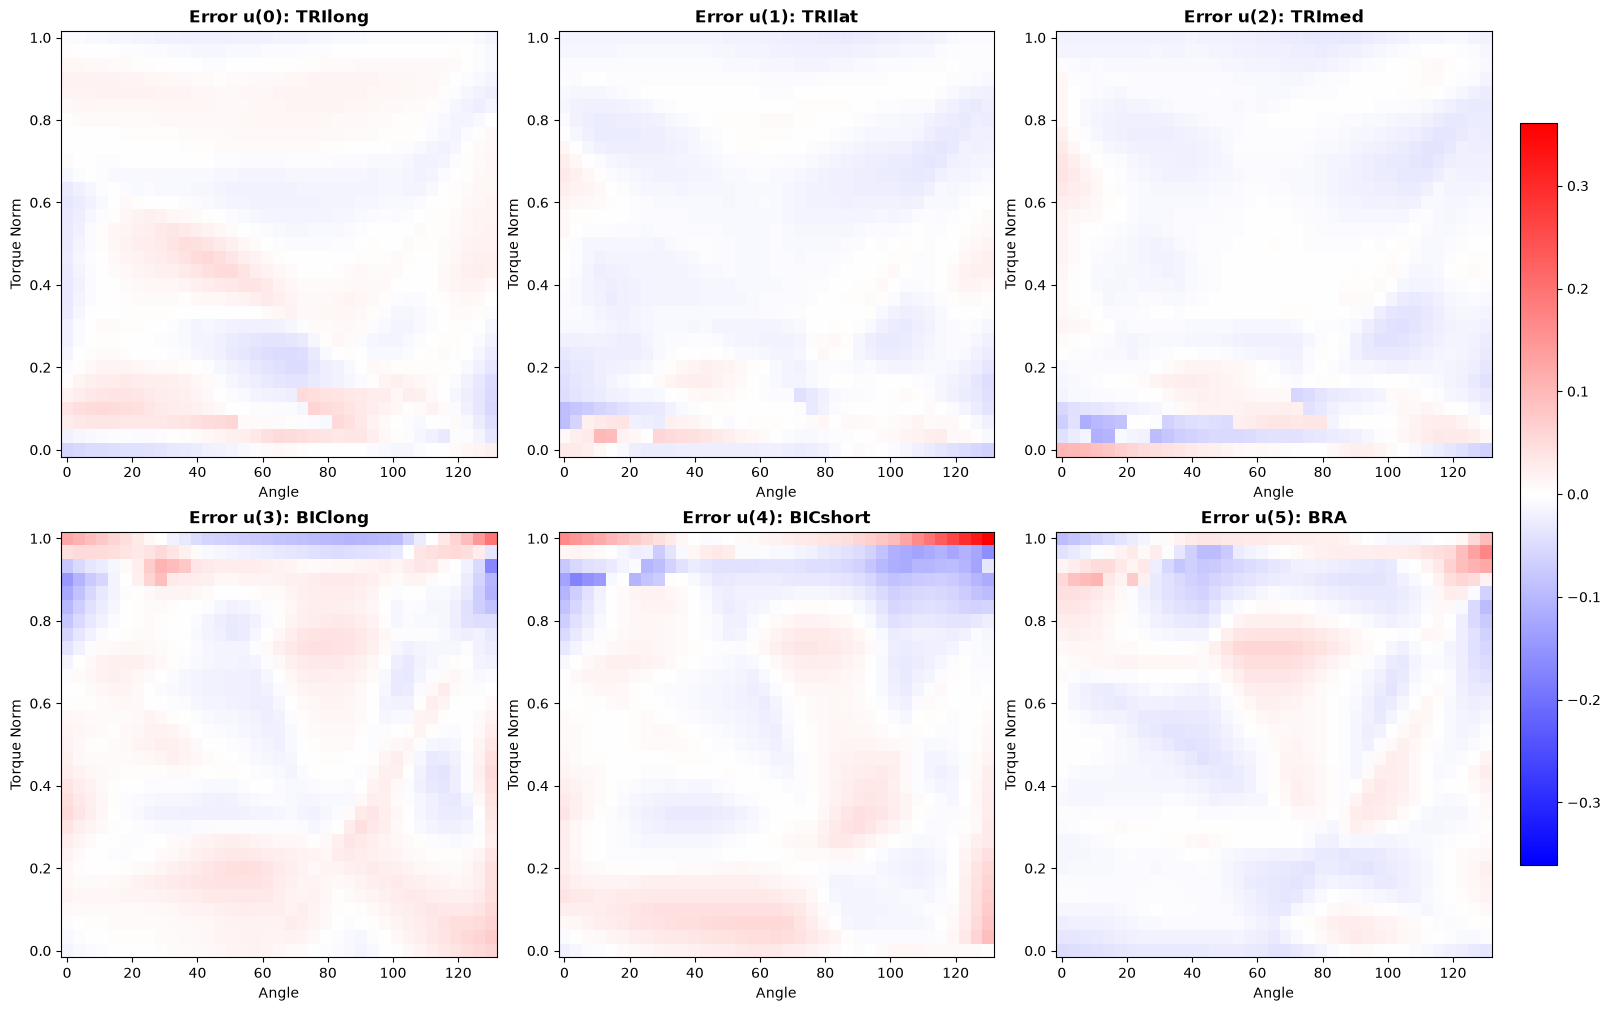

In [97]:

#my_nn_model.plot_heatmaps()
my_nn_model.plot_error_heatmaps()
#my_nn_model.plot_error_heatmaps(save_path=PATH_PLOT_SAVED)